# PBAAnalysisSentiment: pipeline lengkap (label → cleaning → cluster → resample → fine-tune IndoBERTweet)

Klasifikasi sentimen **negatif / positif** untuk komentar TikTok tentang Prabowo, dalam **satu notebook** yang dijalankan dari atas ke bawah (*Run All*).

Setiap tahap:
- **mencari path sendiri** (tidak ada path Windows yang ditulis mati), asal notebook dijalankan dari dalam folder project,
- **dilewati kalau hasilnya sudah ada**, jadi aman diulang. Untuk memaksa ulang, tambahkan nama tahap ke `FORCE`,
- **menyesuaikan mesin**: GPU NVIDIA (CUDA), Apple Silicon (MPS), atau CPU saja. Ollama bersifat **opsional**.

| # | Tahap | Masuk | Keluar (di `data/praprocessing/<dataset>/` kecuali disebut lain) |
|---|---|---|---|
| 1 | Agregasi label antar-annotator, kappa | `labeling/labels_<nama>.csv` | `data/labeled/labels_<...>_<strategi>.csv` |
| 2 | Cleaning + split stratified (referensi) | file tahap 1 | `train_raw.csv`, `test_raw.csv` |
| 3 | Cleaning, buang netral, embedding bge-m3, clustering per label | file tahap 1 | `clustered.csv`, `embeddings_bge-m3.npy` |
| 4 | Split per cluster, undersample negatif, oversample positif (LLM) | `clustered.csv` | `train_balanced.csv`, `test_final.csv`, `synthetic_positives.csv` |
| 5 | Positif *targeted* untuk slice yang bias negatif (mis. `mbg`) | `train_balanced.csv` | `targeted_positives.csv` |
| 6 | Fine-tune IndoBERTweet, eksperimen multi-seed, evaluasi, analisis error | tahap 4-5 | `model_indobertweet/<run>/` |

## Struktur folder yang diharapkan
```
<project>/
├─ labeling/labels_<nama>.csv        # satu file per annotator (kolom: comment_text, label, + metadata)
├─ data/labeled/                     # keluaran tahap 1 (atau taruh CSV berlabel sendiri di sini)
├─ data/praprocessing/<dataset>/     # keluaran tahap 2-6
└─ PBAAnalysisSentiment_pipeline.ipynb
```
Kalau kamu sudah punya CSV berlabel (kolom wajib: `comment_text`, `final_label` ∈ {positif, negatif, netral}), taruh di `data/labeled/` lalu isi `INPUT_FILENAME` di sel konfigurasi. Tahap 1 otomatis dilewati.

## Kebutuhan
- Python 3.10+. Paket ringan dipasang otomatis (`AUTO_INSTALL = True`): `numpy pandas scikit-learn requests tqdm matplotlib emoji transformers`.
- **PyTorch**: dipasang otomatis di awal tahap 6 (build CUDA kalau ada GPU NVIDIA, selain itu build CPU/MPS). Setelah pemasangan pertama, **restart kernel** lalu *Run All* lagi.
- **Ollama (opsional)** di <http://localhost:11434>, untuk embedding (`ollama pull bge-m3`) dan data sintetis (`ollama pull qwen2.5:7b`).
  Tanpa Ollama: embedding pakai `BAAI/bge-m3` dari Hugging Face (`sentence-transformers`, unduhan ±2 GB), dan generate data sintetis dilewati.
- GPU 6 GB cukup (batch 8 × akumulasi 2, fp16). CPU saja tetap jalan tapi **lambat**: satu run fine-tune bisa puluhan menit, jadi sweep otomatis dipersingkat jadi 1 seed.

## Aman untuk GitHub
- Data berisi **komentar & username orang lain**. Sel setup menambahkan `data/`, `labeling/`, model, dan embedding ke `.gitignore` (hanya kalau project ini repo git).
- Kalau `data/` sudah pernah ter-commit: `git rm -r --cached data labeling`.
- Notebook ini dikirim **tanpa output**. Sebelum commit setelah dijalankan: *Clear All Outputs*, karena output memuat potongan komentar dan path komputermu.
- 80 komentar *targeted* di tahap 5 adalah **data sintetis tulisan tangan (bukan data asli)**. Sebut begitu di laporan/paper.

In [1]:
# ===== SETUP UMUM: import + pemasang paket ringan =====
import os, sys, re, json, math, random, time, gc, shutil, subprocess, platform, warnings, importlib, importlib.util
from pathlib import Path
from collections import Counter
from itertools import combinations
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

AUTO_INSTALL = True      # True = pasang otomatis paket Python yang kurang (pip). False = hanya beri tahu perintahnya.

class StopNotebook(Exception):
    """Menghentikan 'Run All' dengan pesan rapi (bukan traceback panjang)."""
    def __init__(self, msg=""): super().__init__(msg); self.msg = msg
    def _render_traceback_(self): return ["BERHENTI: " + self.msg]

def pip_install(*pkgs):
    cmd = [sys.executable, "-m", "pip", "install", *pkgs]
    print("$", " ".join(cmd))
    ok = subprocess.run(cmd).returncode == 0
    importlib.invalidate_caches()
    return ok

def ensure(mods):
    """mods = {nama_import: nama_pip}. Pasang yang belum ada."""
    missing = {m: p for m, p in mods.items() if importlib.util.find_spec(m) is None}
    if not missing: return
    names = " ".join(missing.values())
    if not AUTO_INSTALL:
        raise ModuleNotFoundError(f"Paket belum terpasang. Jalankan: {sys.executable} -m pip install {names}")
    pip_install(*missing.values())
    still = [p for m, p in missing.items() if importlib.util.find_spec(m) is None]
    if still:
        raise ModuleNotFoundError(f"Gagal memasang: {' '.join(still)}. Coba manual: {sys.executable} -m pip install {' '.join(still)}")

ensure({"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "requests": "requests",
        "tqdm": "tqdm", "matplotlib": "matplotlib"})
import numpy as np, pandas as pd, requests
print("Python", platform.python_version(), "|", platform.system())

Python 3.13.7 | Windows


In [2]:
# ============================ KONFIGURASI (satu-satunya sel yang biasanya perlu diubah) ============================

# --- Lokasi ---
PROJECT_DIR_OVERRIDE = None   # None = dicari otomatis. Isi kalau salah, mis. r"C:\Users\kamu\PBAAnalysisSentiment"
INPUT_FILENAME = None         # None -> "labels_<annotator>_<strategi>.csv". Isi kalau punya CSV berlabel sendiri di data/labeled/

# --- Tahap yang dijalankan. FORCE = buat ulang walau hasil lama ada ---
RUN   = {"agregasi": True, "split_raw": True, "cluster": True, "resample": True, "targeted": True, "train": True}
FORCE = set()                 # isi dengan kunci RUN, atau "synthetic" (generate ulang data sintetis). Contoh: {"cluster", "resample"}

# --- Tahap 1: agregasi label ---
LABELERS   = ["shafwa", "hans"]
STRATEGY   = "agreement"      # 2 annotator: agreement | all_marked | all_<nama>   |   3+ annotator: unanimous | majority | plurality
CATEGORIES = ["positif", "netral", "negatif"]
SHOW_ALL_KAPPA = True         # tampilkan kappa semua kombinasi annotator yang tersedia

# --- Tahap 2-3: cleaning, embedding, cluster ---
DROP_LABELS   = ["netral"]
RAW_TEST_SIZE = 0.20          # hanya untuk split stratified referensi (tahap 2)
EMBED_MODEL   = "bge-m3"      # nama di Ollama
EMBED_BACKEND = "auto"        # "auto" = Ollama kalau ada, kalau tidak Hugging Face | "ollama" | "hf"
SIM_THRESHOLD = 0.70          # cosine similarity >= ini dianggap satu konteks (0.80 terlalu ketat: ~92% singleton)
SHOW_CLUSTER_EXAMPLES = True

# --- Tahap 4: split per cluster, undersample, oversample ---
SEED = 42                     # seed split & inisialisasi model
VAL_SEED = 42                 # seed split validasi. JANGAN diubah antar run (val harus sama)
TEST_SIZE  = 0.20
TARGET_NEG = 750
TARGET_POS = 750
GENERATE_SYNTHETIC = True     # butuh Ollama + LLM_MODEL. Tidak ada Ollama -> dilewati otomatis (hanya positif asli)

# --- Ollama (opsional) ---
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://localhost:11434")
LLM_MODEL  = "qwen2.5:7b"

# --- Tahap 5: positif targeted ---
TARGETED_SOURCE = "bundled"   # "bundled" = 80 komentar MBG tulisan tangan yang tertanam di notebook | "llm" = generate via Ollama | "none"
FORCE_KEYWORDS, EXTRA_KEYWORDS, DROP_KEYWORDS = ["mbg"], [], []     # kata fokus dipilih MANUAL: topik netral, bukan kata bermakna negatif
MIN_COUNT, SKEW_RATIO, AUTO_TOP = 15, 0.5, 0                         # pencarian kata bias (AUTO_TOP=0: tidak otomatis)
TARGET_SHARE, MAX_PER_KEYWORD, MAX_TOTAL = 0.25, 60, 150             # hanya untuk TARGETED_SOURCE="llm"
BATCH_K, MAX_TRIES = 8, 40
GLOSSARY = ("MBG = Makan Bergizi Gratis, program pemerintah yang membagikan makanan bergizi gratis untuk anak sekolah dan kelompok rentan. "
            "SPPG = Satuan Pelayanan Pemenuhan Gizi (dapur penyedia MBG). MBG adalah PROGRAM, bukan nama orang.")

# --- Tahap 6: model & eksperimen ---
MODEL_NAME = "indolem/indobertweet-base-uncased"
EPOCHS, LR, MAX_LEN, WARMUP_RATIO = 3, 2e-5, 96, 0.1
BATCH_SIZE, GRAD_ACCUM = 8, 2            # batch efektif 16. Kecil = VRAM & panas lebih rendah
TRAIN_MODE    = "sweep"                  # "sweep" (config x seed) | "single" (satu run) | "off" (hanya analisis run yang ada)
SYN_MODE      = "none"                   # untuk "single": "none" | "generic" | "targeted" | "both"
CLASS_WEIGHT  = True                     # untuk "single"
SWEEP_CONFIGS = [("none", True), ("targeted", True)]    # (syn_mode, class_weight); run yang sudah ada dilewati
SWEEP_SEEDS   = [42, 43, 44]
CPU_ONE_SEED  = True                     # mesin tanpa GPU: sweep hanya seed pertama (CPU lambat)

# --- Perangkat keras ---
USE_FP16_PREF = True                     # dipakai hanya di GPU NVIDIA
GPU_SAFE_MODE = True                     # True = batas suhu + jeda pendinginan (laptop gaming). False = tanpa jeda (PC desktop / cloud)
TEMP_PAUSE, TEMP_RESUME, TEMP_ABORT = 78, 72, 86    # TEMP_RESUME harus di atas suhu idle mesinmu
STEP_SLEEP_S, EPOCH_COOLDOWN_S, RUN_COOLDOWN_S, CHECK_EVERY = 0.05, 60, 90, 10

WRITE_GITIGNORE = True                   # tambahkan data/, labeling/, model ke .gitignore (hanya jika repo git)

In [3]:
# ===== PATH OTOMATIS + helper bersama =====
def find_project_root():
    if PROJECT_DIR_OVERRIDE: return Path(PROJECT_DIR_OVERRIDE).expanduser().resolve()
    here = Path.cwd().resolve()
    chain = [here, *here.parents]
    for base in chain:                       # folder yang punya labeling/ atau data/labeled|praprocessing
        if (base/"labeling").is_dir() or (base/"data"/"labeled").is_dir() or (base/"data"/"praprocessing").is_dir():
            return base
    for base in chain:                       # lalu akar repo git
        if (base/".git").exists(): return base
    return here

ROOT         = find_project_root()
LABELING_DIR = ROOT / "labeling"
LABELED_DIR  = ROOT / "data" / "labeled"
PRAPROC_DIR  = ROOT / "data" / "praprocessing"
if INPUT_FILENAME is None:
    INPUT_FILENAME = f"labels_{'_'.join(LABELERS)}_{STRATEGY}.csv"
INPUT_PATH   = LABELED_DIR / INPUT_FILENAME
DATASET_NAME = INPUT_PATH.stem
DATA_DIR     = PRAPROC_DIR / DATASET_NAME        # semua keluaran tahap 2-6
MODEL_DIR    = DATA_DIR / "model_indobertweet"

print("Folder project :", ROOT)
print("File berlabel  :", INPUT_PATH, "(ada)" if INPUT_PATH.exists() else "(belum ada -> dibuat di tahap 1)")
print("Folder keluaran:", DATA_DIR)

# ---------- .gitignore ----------
GITIGNORE_BLOCK = """# >>> PBAAnalysisSentiment (otomatis) >>>
# data berisi komentar & username orang lain, jangan di-push
labeling/
data/
# berkas besar hasil proses
model_indobertweet/
*.npy
.venv/
venv/
__pycache__/
.ipynb_checkpoints/
# <<< PBAAnalysisSentiment <<<
"""
def _in_git_repo():
    return any((b/".git").exists() for b in [ROOT, *ROOT.parents])
if WRITE_GITIGNORE:
    gi = ROOT / ".gitignore"
    cur = gi.read_text(encoding="utf-8") if gi.exists() else ""
    if not _in_git_repo():
        print(".gitignore: bukan repo git, dilewati.")
    elif ">>> PBAAnalysisSentiment" in cur:
        print(".gitignore: blok sudah ada.")
    else:
        gi.write_text(cur + ("\n" if cur and not cur.endswith("\n") else "") + GITIGNORE_BLOCK, encoding="utf-8")
        print(".gitignore: blok data/ labeling/ model ditambahkan di", gi)

# ---------- teks ----------
def clean_text(t):
    t = str(t).replace("\u200b", "")          # zero-width space
    return re.sub(r"\s+", " ", t).strip()

def norm(t): return re.sub(r"\s+", " ", str(t).lower()).strip()
def toks(t): return set(re.findall(r"\w+|\?", norm(t)))
def jacc(a, b): return len(a & b) / max(len(a | b), 1)

# ---------- suhu GPU NVIDIA (kalau ada) ----------
def gpu_temp():
    if not shutil.which("nvidia-smi"): return None
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                             capture_output=True, text=True, timeout=5).stdout.strip().splitlines()
        return int(out[0])
    except Exception:
        return None

def cool_guard():
    """Jeda sampai GPU turun (hanya kalau GPU_SAFE_MODE dan ada nvidia-smi)."""
    if not GPU_SAFE_MODE: return
    t = gpu_temp()
    if t is not None and t >= TEMP_PAUSE:
        print(f"\n  GPU {t}C, jeda sampai <= {TEMP_RESUME}C ...", end="")
        while True:
            time.sleep(10); t = gpu_temp()
            if t is None or t <= TEMP_RESUME: break
        print(f" lanjut ({t}C)")

LLM_PAUSE_S = 2 if GPU_SAFE_MODE else 0

# ---------- Ollama (opsional) ----------
_http = requests.Session(); _http.trust_env = False        # abaikan proxy sistem untuk localhost

def ollama_models():
    try:
        r = _http.get(f"{OLLAMA_URL}/api/tags", timeout=5); r.raise_for_status()
        return [m["name"] for m in r.json().get("models", [])]
    except Exception:
        return None

def ollama_has(model):
    names = ollama_models()
    if names is None: return False
    return model in names or f"{model}:latest" in names or (":" not in model and any(n.split(":")[0] == model for n in names))

def llm(prompt, temperature=0.9, timeout=600):
    r = _http.post(f"{OLLAMA_URL}/api/generate", timeout=timeout,
                   json={"model": LLM_MODEL, "prompt": prompt, "stream": False,
                         "options": {"temperature": temperature, "top_p": 0.95}})
    r.raise_for_status()
    return r.json()["response"]

def clean_line(s):
    return re.sub(r"^\s*(?:[-*•]|\d+[.)])\s*", "", s).strip().strip('"').strip()

def vc(s):
    """value_counts sebagai dict Python biasa (cetakan lebih rapi)."""
    return {k: int(v) for k, v in s.value_counts().items()}

_names = ollama_models()
print("\nOllama:", "tidak terjangkau (opsional)" if _names is None else f"OK, model: {_names}")
if _names is not None:
    for m, untuk in ((EMBED_MODEL, "embedding"), (LLM_MODEL, "data sintetis")):
        if not ollama_has(m): print(f"  - {m} belum ada untuk {untuk}. Jalankan: ollama pull {m}")

Folder project : C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment
File berlabel  : C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment\data\labeled\labels_shafwa_hans_agreement.csv (ada)
Folder keluaran: C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment\data\praprocessing\labels_shafwa_hans_agreement
.gitignore: blok data/ labeling/ model ditambahkan di C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment\.gitignore

Ollama: OK, model: ['qwen2.5:7b', 'bge-m3:latest', 'llama3.1:latest']


## Tahap 1. Agregasi label antar-annotator

Membaca `labeling/labels_<nama>.csv`, menghitung **Fleiss' kappa** tiap kombinasi annotator (baris yang dipakai = panjang minimum di antara annotator dalam kombinasi itu),
lalu menggabungkan label sesuai `STRATEGY`. Untuk 2 annotator, `agreement` hanya menyimpan komentar yang disepakati keduanya.

In [4]:
def fleiss_kappa(counts):
    counts = np.asarray(counts, dtype=float)
    N, _ = counts.shape; n = counts[0].sum()
    p_j = counts.sum(axis=0) / (N * n)
    P_i = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    P_e = (p_j ** 2).sum()
    return float((P_i.mean() - P_e) / (1 - P_e))

def interp(k):
    return "Poor" if k < .2 else "Fair" if k < .4 else "Moderate" if k < .6 else "Substantial" if k < .8 else "Almost Perfect"

def stage1_agregasi():
    if INPUT_PATH.exists() and "agregasi" not in FORCE:
        print(f"[1] {INPUT_PATH.name} sudah ada -> dilewati (tambahkan 'agregasi' ke FORCE untuk membuat ulang)"); return
    files = sorted(LABELING_DIR.glob("labels_*.csv")) if LABELING_DIR.is_dir() else []
    if not files:
        raise FileNotFoundError(
            f"Tidak ada berkas label.\n  Perlu salah satu:\n  a) {LABELING_DIR}\\labels_<nama>.csv (satu per annotator), atau\n"
            f"  b) CSV berlabel di {LABELED_DIR} lalu isi INPUT_FILENAME (kolom: comment_text, final_label).")
    raw = {f.stem[len("labels_"):]: pd.read_csv(f, dtype=str, encoding="utf-8") for f in files}
    for n, d in raw.items():
        if not {"comment_text", "label"} <= set(d.columns): raise ValueError(f"labels_{n}.csv butuh kolom comment_text dan label")
    print("Annotator ditemukan:", {n: len(d) for n, d in raw.items()})
    chosen = list(LABELERS)
    miss = [n for n in chosen if n not in raw]
    if miss: raise FileNotFoundError(f"LABELERS {miss} tidak ada di {LABELING_DIR}. Tersedia: {list(raw)}")

    def label_frame(combo, n_rows):
        return pd.DataFrame({n: raw[n]["label"].iloc[:n_rows].reset_index(drop=True).fillna("").str.lower().str.strip() for n in combo})

    def kappa_for(combo):
        n_rows = min(len(raw[n]) for n in combo)
        sub = label_frame(combo, n_rows); sv = sub[sub.isin(CATEGORIES).all(axis=1)]
        if len(sv) == 0: return None, 0, n_rows
        return fleiss_kappa(np.column_stack([(sv == c).sum(axis=1) for c in CATEGORIES])), len(sv), n_rows

    if SHOW_ALL_KAPPA and len(raw) >= 2:
        rows = []
        for r in range(2, len(raw) + 1):
            for combo in combinations(raw, r):
                k, nv, nr = kappa_for(combo)
                if k is not None: rows.append({"annotator": ", ".join(combo), "n_valid": nv, "kappa": round(k, 4), "interpretasi": interp(k)})
        print("\nKappa semua kombinasi:"); print(pd.DataFrame(rows).sort_values("kappa", ascending=False).reset_index(drop=True).to_string())

    k, nv, n_rows = kappa_for(chosen)
    print(f"\nDipilih {chosen}: kappa={k:.4f} ({interp(k)}) | baris valid {nv} dari {n_rows}")
    sub = label_frame(chosen, n_rows)
    valid = sub.isin(CATEGORIES).all(axis=1)
    # baris tiap annotator harus sejajar (komentar sama di baris sama)
    base_txt = raw[chosen[0]]["comment_text"].iloc[:n_rows].reset_index(drop=True).map(norm)
    for n in chosen[1:]:
        bad = int((raw[n]["comment_text"].iloc[:n_rows].reset_index(drop=True).map(norm) != base_txt).sum())
        if bad: print(f"PERINGATAN: {bad} baris komentar {n} berbeda dari {chosen[0]} (baris tidak sejajar?)")

    votes = pd.DataFrame({c: (sub == c).sum(axis=1) for c in CATEGORIES})
    n = len(chosen); top = votes.max(axis=1); n_top = (votes == top.values[:, None]).sum(axis=1); modus = votes.idxmax(axis=1)
    if n == 2:
        a, b = chosen
        agree = valid & (sub[a] == sub[b])
        strategies = {"agreement": ("hanya yang disepakati", agree, modus),
                      "all_marked": ("semua + DISAGREEMENT ditandai", valid, sub[a].where(agree, "DISAGREEMENT")),
                      f"all_{a}": (f"semua, label dari {a}", valid, sub[a]),
                      f"all_{b}": (f"semua, label dari {b}", valid, sub[b])}
    else:
        strategies = {"unanimous": ("bulat", valid & (top == n), modus),
                      "majority": ("mayoritas", valid & (top > n / 2), modus),
                      "plurality": ("suara terbanyak tunggal", valid & (n_top == 1), modus)}
    prev = [{"strategi": key, "keterangan": d, **{c: int((f[m] == c).sum()) for c in CATEGORIES + ["DISAGREEMENT"]}, "total": int(m.sum())}
            for key, (d, m, f) in strategies.items()]
    print("\nPratinjau strategi:"); print(pd.DataFrame(prev).set_index("strategi").to_string())
    if STRATEGY not in strategies: raise ValueError(f"STRATEGY '{STRATEGY}' tidak valid untuk {n} annotator. Pilihan: {list(strategies)}")

    desc, mask, fin = strategies[STRATEGY]
    meta_cols = [c for c in ["post_url", "username", "comment_text", "timestamp", "likes_count"] if c in raw[chosen[0]].columns]
    out = raw[chosen[0]][meta_cols].iloc[:n_rows].reset_index(drop=True)[mask].copy()
    for nm in chosen: out[f"label_{nm}"] = sub.loc[mask, nm].values
    for c in CATEGORIES: out[f"votes_{c}"] = votes.loc[mask, c].values
    out["final_label"] = fin[mask].values
    LABELED_DIR.mkdir(parents=True, exist_ok=True)
    out.to_csv(INPUT_PATH, index=False, encoding="utf-8")
    print(f"\nTersimpan: {INPUT_PATH} ({len(out)} baris)")
    print(out["final_label"].value_counts().to_string())

if RUN["agregasi"]: stage1_agregasi()
else: print("[1] dinonaktifkan di RUN")

[1] labels_shafwa_hans_agreement.csv sudah ada -> dilewati (tambahkan 'agregasi' ke FORCE untuk membuat ulang)


## Tahap 2. Cleaning + split stratified (referensi)

Cleaning ringan (IndoBERTweet sudah terlatih di teks media sosial, jadi emoji/URL/mention dibiarkan): rapikan spasi, buang kosong, buang duplikat teks.
Lalu split **stratified** per label → `train_raw.csv` / `test_raw.csv`.

> Split ini hanya **pembanding**. Model final memakai split **per cluster** (tahap 4) supaya komentar yang mirip tidak bocor antara train dan test.

In [5]:
def stage2_split_raw():
    from sklearn.model_selection import train_test_split
    tr_p, te_p = DATA_DIR / "train_raw.csv", DATA_DIR / "test_raw.csv"
    if tr_p.exists() and te_p.exists() and "split_raw" not in FORCE:
        print("[2] train_raw/test_raw sudah ada -> dilewati"); return
    if not INPUT_PATH.exists(): raise FileNotFoundError(f"{INPUT_PATH} tidak ada. Jalankan tahap 1.")
    df = pd.read_csv(INPUT_PATH, dtype=str, encoding="utf-8")
    d = df[df["comment_text"].notna() & df["final_label"].notna()].copy()
    d["comment_text"] = d["comment_text"].map(clean_text); d = d[d["comment_text"] != ""]
    n1 = len(d)
    conf = d.groupby("comment_text")["final_label"].nunique(); conf = conf[conf > 1]
    d = d.drop_duplicates(subset=["comment_text"], keep="first").reset_index(drop=True)
    print(f"Awal {len(df)} -> buang kosong/NaN {n1} -> buang duplikat {len(d)} | komentar sama tapi label beda: {len(conf)}")
    strat = d["final_label"] if d["final_label"].value_counts().min() >= 2 else None
    if strat is None: print("PERINGATAN: ada label dengan <2 contoh, split tidak stratified")
    train, test = train_test_split(d, test_size=RAW_TEST_SIZE, random_state=SEED, stratify=strat)
    train, test = train.reset_index(drop=True), test.reset_index(drop=True)
    print(pd.DataFrame({"train": train["final_label"].value_counts(), "test": test["final_label"].value_counts()}).to_string())
    print("Komentar overlap train/test:", len(set(train["comment_text"]) & set(test["comment_text"])))
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    train.to_csv(tr_p, index=False, encoding="utf-8"); test.to_csv(te_p, index=False, encoding="utf-8")
    print("Tersimpan:", tr_p.name, len(train), "|", te_p.name, len(test))

if RUN["split_raw"]: stage2_split_raw()
else: print("[2] dinonaktifkan di RUN")

[2] train_raw/test_raw sudah ada -> dilewati


## Tahap 3. Cleaning, buang netral, embedding, clustering

- Buang kelas netral dan duplikat persis.
- **Embedding** tiap komentar dengan `bge-m3` (1024 dimensi), di-*cache* ke `.npy` supaya run ulang tidak meng-embed lagi. Backend: Ollama bila tersedia, kalau tidak Hugging Face.
- **Clustering** agglomerative (cosine, linkage average) **per label** dengan ambang `SIM_THRESHOLD`. Komentar dengan similarity ≥ ambang dianggap satu konteks (spam, copy-paste, variasi kecil).

In [6]:
def embed_ollama(texts, batch=32):
    out = []
    for i in range(0, len(texts), batch):
        r = _http.post(f"{OLLAMA_URL}/api/embed", json={"model": EMBED_MODEL, "input": texts[i:i+batch]}, timeout=300)
        r.raise_for_status(); out.extend(r.json()["embeddings"])
        print(f"\r  embedded {min(i+batch, len(texts))}/{len(texts)}", end="")
    print(); return np.array(out, dtype=np.float32)

def embed_hf(texts):
    ensure({"sentence_transformers": "sentence-transformers"})
    import torch
    from sentence_transformers import SentenceTransformer
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"  Hugging Face BAAI/bge-m3 di {dev} (unduhan pertama ±2 GB)")
    m = SentenceTransformer("BAAI/bge-m3", device=dev); m.max_seq_length = 256
    return m.encode(texts, batch_size=32 if dev == "cuda" else 8, normalize_embeddings=True, show_progress_bar=True).astype(np.float32)

def get_embeddings(texts):
    backend = EMBED_BACKEND
    if backend == "auto": backend = "ollama" if ollama_has(EMBED_MODEL) else "hf"
    print("  backend embedding:", backend)
    if backend == "ollama":
        if not ollama_has(EMBED_MODEL): raise RuntimeError(f"Ollama/model belum siap. Jalankan: ollama pull {EMBED_MODEL}  (atau EMBED_BACKEND='hf')")
        return embed_ollama(texts)
    return embed_hf(texts)

def cluster_ids(E, sim_thr):
    from sklearn.cluster import AgglomerativeClustering
    if len(E) == 1: return np.array([0])
    return AgglomerativeClustering(n_clusters=None, distance_threshold=1 - sim_thr, metric="cosine", linkage="average").fit_predict(E)

def stage3_cluster():
    out_path = DATA_DIR / "clustered.csv"
    if out_path.exists() and "cluster" not in FORCE:
        print(f"[3] clustered.csv sudah ada -> dilewati ({len(pd.read_csv(out_path))} baris)"); return
    if not INPUT_PATH.exists(): raise FileNotFoundError(f"{INPUT_PATH} tidak ada. Jalankan tahap 1.")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(INPUT_PATH, dtype=str, encoding="utf-8")
    d = df[df["comment_text"].notna() & df["final_label"].notna()].copy()
    d["comment_text"] = d["comment_text"].map(clean_text)
    d = d[(d["comment_text"] != "") & ~d["final_label"].isin(DROP_LABELS)]
    n1 = len(d); d = d.drop_duplicates(subset=["comment_text"], keep="first").reset_index(drop=True)
    print(f"Awal {len(df)} -> buang kosong/{DROP_LABELS} {n1} -> buang duplikat {len(d)}"); print(d["final_label"].value_counts().to_string())

    emb_path, txt_path = DATA_DIR / f"embeddings_{EMBED_MODEL.replace(':', '_')}.npy", DATA_DIR / "embeddings_texts.csv"
    if emb_path.exists() and txt_path.exists() and pd.read_csv(txt_path, encoding="utf-8")["comment_text"].tolist() == d["comment_text"].tolist():
        emb = np.load(emb_path); print("Pakai cache embedding:", emb.shape)
    else:
        print("Embedding", len(d), "komentar ...")
        emb = get_embeddings(d["comment_text"].tolist())
        np.save(emb_path, emb); d[["comment_text"]].to_csv(txt_path, index=False, encoding="utf-8")
    emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)           # L2 -> cosine = dot product

    rows = []                                                         # sweep ambang (membantu memilih SIM_THRESHOLD)
    for lab in sorted(d["final_label"].unique()):
        E = emb[(d["final_label"] == lab).values]
        for thr in [0.70, 0.75, 0.80, 0.85, 0.90]:
            sizes = np.bincount(cluster_ids(E, thr))
            rows.append({"label": lab, "threshold": thr, "n_komentar": len(E), "n_cluster": len(sizes),
                         "singleton": int((sizes == 1).sum()), "cluster_terbesar": int(sizes.max())})
    print("\nSweep ambang:"); print(pd.DataFrame(rows).to_string(index=False))

    d["cluster_id"] = ""
    for lab in sorted(d["final_label"].unique()):
        idx = np.where((d["final_label"] == lab).values)[0]
        d.loc[idx, "cluster_id"] = [f"{lab}_{x:04d}" for x in cluster_ids(emb[idx], SIM_THRESHOLD)]
    d["cluster_size"] = d.groupby("cluster_id")["comment_text"].transform("size"); d["panjang"] = d["comment_text"].str.len()
    print(f"\nCluster final (SIM_THRESHOLD={SIM_THRESHOLD}):"); print(d.groupby("final_label")["cluster_id"].nunique().to_string())

    if SHOW_CLUSTER_EXAMPLES:
        lab = "negatif" if (d["final_label"] == "negatif").any() else d["final_label"].iloc[0]
        big = d[d["final_label"] == lab].groupby("cluster_id").size().sort_values(ascending=False).head(6)
        for cid, size in big.items():
            print(f"\n=== {cid} | {size} komentar ===")
            for t in d[d["cluster_id"] == cid].sort_values("panjang", ascending=False)["comment_text"].head(4): print("  -", t[:140])
    d.to_csv(out_path, index=False, encoding="utf-8")
    print("\nTersimpan:", out_path, f"({len(d)} baris; urutan baris sama dengan {emb_path.name})")

if RUN["cluster"]: stage3_cluster()
else: print("[3] dinonaktifkan di RUN")

[3] clustered.csv sudah ada -> dilewati (1835 baris)


## Tahap 4. Split per cluster, undersample negatif, oversample positif

1. **Split per cluster** (`GroupShuffleSplit`): satu cluster seluruhnya masuk train **atau** test, jadi komentar mirip tidak bocor. **Test tidak di-resample** (distribusi asli).
2. **Undersample negatif** (khusus train) ke `TARGET_NEG`: 1 wakil per cluster dulu, sisa kuota dari cluster besar. Variasi terjaga, spam tidak mendominasi.
3. **Oversample positif** (khusus train) ke `TARGET_POS` dengan komentar sintetis dari LLM lokal. Hasilnya di-*cache* di `synthetic_positives.csv`. Tanpa Ollama, tahap ini dilewati dan train hanya berisi positif asli.
   Kolom `sumber` menandai asal data: `asli` / `synthetic`.

> Jangan hapus `train_balanced.csv` di tengah eksperimen: set validasi diturunkan dari urutan barisnya, jadi membuat ulang file ini (apalagi dengan data sintetis yang berbeda) mengubah val dan membuat run lama tidak sebanding.

In [7]:
SYN_PROMPT = """Kamu membantu membuat data latih analisis sentimen komentar TikTok berbahasa Indonesia tentang Prabowo.
Berikut contoh komentar ASLI dengan sentimen POSITIF:
{ex}

Tulis {k} komentar BARU dengan sentimen POSITIF terhadap Prabowo. Aturan:
- gaya bahasa seperti komentar TikTok asli (santai, singkat, boleh slang/emoji)
- topik dan kalimat harus beragam, jangan meniru contoh kata per kata
- satu komentar per baris, tanpa nomor, tanpa penjelasan"""

def undersample_by_cluster(d, target, seed=SEED):
    d = d.sample(frac=1, random_state=seed).reset_index(drop=True)
    first = d.groupby("cluster_id", sort=False).head(1)               # 1 wakil per cluster
    if len(first) >= target: return first.sample(n=target, random_state=seed)
    rest = d.drop(first.index)
    size = d["cluster_id"].map(d["cluster_id"].value_counts())
    rest = rest.assign(_w=size.loc[rest.index].values)
    need = target - len(first)
    if need >= len(rest):                                             # kuota melebihi sisa data -> ambil semua
        extra = rest.drop(columns="_w")
    else:
        try:
            extra = rest.sample(n=need, weights="_w", random_state=seed).drop(columns="_w")
        except ValueError:                                            # pandas menolak bobot yang terlalu timpang -> sampling berbobot alternatif
            keys = np.random.RandomState(seed).random_sample(len(rest)) ** (1.0 / rest["_w"].values)
            extra = rest.iloc[np.argsort(-keys)[:need]].drop(columns="_w")
    return pd.concat([first, extra])

def generate_synthetic(pos_real, test, n_need):
    random.seed(SEED)
    seen = set(pos_real["comment_text"].str.lower()) | set(test["comment_text"].str.lower())
    pool, out, tries = pos_real["comment_text"].tolist(), [], 0
    while len(out) < n_need and tries < 80:
        tries += 1
        ex = random.sample(pool, k=min(8, len(pool)))
        try:
            lines = [clean_line(l) for l in llm(SYN_PROMPT.format(ex="\n".join(f"- {e}" for e in ex), k=15)).splitlines()]
        except Exception as e:
            print("\n  gagal batch:", e); continue
        for c in lines:
            if 5 <= len(c) <= 300 and not c.lower().startswith(("berikut", "tentu", "note", "catatan")) and c.lower() not in seen:
                seen.add(c.lower()); out.append(c)
        print(f"\r  synthetic {min(len(out), n_need)}/{n_need} (batch {tries})", end="")
        cool_guard(); time.sleep(LLM_PAUSE_S)
    print(); return out[:n_need]

def stage4_resample():
    from sklearn.model_selection import GroupShuffleSplit
    tr_p, te_p = DATA_DIR / "train_balanced.csv", DATA_DIR / "test_final.csv"
    if tr_p.exists() and te_p.exists() and "resample" not in FORCE:
        print("[4] train_balanced.csv & test_final.csv sudah ada -> dilewati (agar val/test tetap sama dengan run sebelumnya)"); return
    cl_p = DATA_DIR / "clustered.csv"
    if not cl_p.exists(): raise FileNotFoundError(f"{cl_p} tidak ada. Jalankan tahap 3.")
    random.seed(SEED); np.random.seed(SEED)
    df = pd.read_csv(cl_p, encoding="utf-8")
    assert {"comment_text", "final_label", "cluster_id"} <= set(df.columns), "kolom wajib tidak lengkap"

    gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
    tr_idx, te_idx = next(gss.split(df, groups=df["cluster_id"]))
    train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
    assert set(train["cluster_id"]).isdisjoint(set(test["cluster_id"])) and set(train["comment_text"]).isdisjoint(set(test["comment_text"]))
    print("Train:", len(train), vc(train["final_label"]), "| Test:", len(test), vc(test["final_label"]))

    neg_all = train[train["final_label"] == "negatif"]
    neg_bal = undersample_by_cluster(neg_all, TARGET_NEG)
    print(f"Negatif: {len(neg_all)} -> {len(neg_bal)} | cluster terwakili {neg_bal['cluster_id'].nunique()}/{neg_all['cluster_id'].nunique()}")

    pos_real = train[train["final_label"] == "positif"].reset_index(drop=True)
    n_need = TARGET_POS - len(pos_real)
    print(f"Positif asli (train): {len(pos_real)} | kekurangan: {max(n_need, 0)}")
    synthetic = []
    if n_need > 0:
        cache = DATA_DIR / "synthetic_positives.csv"
        if cache.exists() and "synthetic" not in FORCE:
            bad = set(pos_real["comment_text"].str.lower()) | set(test["comment_text"].str.lower())
            synthetic = [c for c in pd.read_csv(cache, encoding="utf-8")["comment_text"].tolist() if c.lower() not in bad][:n_need]
            print(f"Pakai cache sintetis: {len(synthetic)} (synthetic_positives.csv)")
        elif GENERATE_SYNTHETIC and ollama_has(LLM_MODEL):
            synthetic = generate_synthetic(pos_real, test, n_need)
            pd.DataFrame({"comment_text": synthetic}).to_csv(cache, index=False, encoding="utf-8")
        else:
            print(f"Data sintetis dilewati (GENERATE_SYNTHETIC={GENERATE_SYNTHETIC}, Ollama/{LLM_MODEL} {'siap' if ollama_has(LLM_MODEL) else 'tidak tersedia'}). "
                  f"Train memakai positif asli saja; mode 'generic'/'both' di tahap 6 tidak berguna tanpa ini.")
    for s in synthetic[:5]: print("  -", s)
    syn_df = pd.DataFrame({"comment_text": synthetic, "final_label": "positif",
                           "cluster_id": [f"positif_syn_{i:04d}" for i in range(len(synthetic))], "sumber": "synthetic"})
    pos_bal = pd.concat([pos_real.assign(sumber="asli"), syn_df], ignore_index=True)
    if len(pos_bal) < TARGET_POS: print(f"PERINGATAN: positif {len(pos_bal)} (< {TARGET_POS})")

    train_balanced = pd.concat([neg_bal.assign(sumber="asli"), pos_bal], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    test_final = test.assign(sumber="asli")
    cols = ["comment_text", "final_label", "cluster_id", "sumber"]
    train_balanced[cols].to_csv(tr_p, index=False, encoding="utf-8"); test_final[cols].to_csv(te_p, index=False, encoding="utf-8")
    print("\ntrain_balanced:", len(train_balanced), vc(train_balanced["final_label"]), "| sumber", vc(train_balanced["sumber"]))
    print("test_final    :", len(test_final), vc(test_final["final_label"]))

if RUN["resample"]: stage4_resample()
else: print("[4] dinonaktifkan di RUN")

[4] train_balanced.csv & test_final.csv sudah ada -> dilewati (agar val/test tetap sama dengan run sebelumnya)


## Tahap 5. Positif *targeted* untuk slice yang bias negatif

**Masalah.** Kata tertentu (mis. `mbg`) di data asli hampir selalu muncul di komentar negatif (±9% positif), jadi model bisa belajar pintasan "ada `mbg` → negatif" dan salah membaca "mbg program bagus".

**Langkah.**
1. Tabel **bias kata** (hanya informasi): kata yang %positifnya jauh di bawah base rate. **Kata fokus dipilih manual** (`FORCE_KEYWORDS`): pilih topik netral, jangan kata bermakna negatif seperti "gagal".
2. Sumber data (`TARGETED_SOURCE`):
   - `"bundled"` (default): **80 komentar positif tentang MBG yang ditulis tangan**, tertanam di notebook. Ini **data sintetis**, bukan komentar asli.
   - `"llm"`: generate via Ollama (dengan glosarium "MBG = program, bukan orang"), dicek ulang sikapnya oleh LLM kedua. Hasil LLM 7B perlu diperiksa mata.
3. Hasil ditulis ke `targeted_positives.csv`. **Buka file itu**; kolom `dipakai = 0` mematikan baris yang janggal. Tahap 6 hanya memakai `dipakai == 1`, dan otomatis membuang baris yang mirip val/test (Jaccard ≥ 0.7).

> Catatan metodologi: memilih `mbg` terinspirasi dari error di test, jadi perbaikan di slice itu cenderung optimistis. Ukur dengan holdout MBG asli yang belum pernah dilihat.

In [8]:
BUNDLED_TARGETED = json.loads(r"""
[
{
"comment_text": "MBG ini beneran bantu banget, anak-anak jadi semangat ke sekolah 🥹",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "alhamdulillah ada mbg, adek saya sekarang sarapan terjamin",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg lanjutkan pak, kami sebagai orang tua terbantu 🙏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "makasih pak prabowo udah bikin mbg, beban emak-emak jadi ringan",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "menu mbg hari ini enak katanya anak saya, lahap bgt makannya",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "program mbg ini langkah yang bagus buat generasi kita ke depan",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "salut sama mbg, gizi anak sekolah akhirnya diperhatiin 👏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "dukung terus mbg sampe ke pelosok ya pak",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mantul mbg, anak sd di kampung kami seneng semua",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "Mbg bikin anak-anak makin rajin berangkat sekolah, bagus ini",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "barakallah buat semua yang kerja di dapur mbg, semoga berkah 🤲",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "ga nyangka mbg udah sampe sekolah kami, makasih pak presiden",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg itu investasi buat anak bangsa, setuju banget",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "tiap lihat anak-anak makan mbg bareng rasanya hangat banget ❤️",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "sehat-sehat terus pak prabowo, mbg-nya terus jalan ya",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "bangga ada program mbg, semoga makin merata",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "anak saya yang biasanya susah makan sayur, di sekolah habis gara-gara mbg 😂",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "makan bergizi gratis ini kebijakan yang pro rakyat banget, mantap pak",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg top, pak prabowo nepatin janjinya 👍",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "ibu hamil sama balita juga kebagian mbg, ini baru peduli rakyat kecil",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "pujian singkat",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "yang nyinyirin mbg coba deh lihat langsung ke sekolah, anak-anak makannya lahap",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "namanya program baru pasti ada kurangnya, tapi mbg arahnya udah bener, kita dukung dulu",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kritik boleh, tapi jangan lupa mbg udah bantu banyak keluarga",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "capek liat orang cuma bisa komen jelek soal mbg, kerja nyata aja belum tentu 🙄",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg dibilang boros? buat gizi anak bangsa menurut saya justru worth it",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "daripada ribut terus, mending bantu awasi biar mbg makin bagus, bukan dijelek-jelekin",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg masih proses berbenah, kasih waktu dong, hasilnya pasti kelihatan",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "saya dukung mbg, perbaikan bisa jalan sambil program tetap lanjut",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "yang bilang mbg gagal belum liat dapurnya langsung kayaknya, rapi dan bersih kok",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "satu dua kasus jangan bikin kita lupa jutaan anak yang kebantu mbg",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg itu niatnya baik, kita doain aja pelaksanaannya makin rapi 🤲",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "ga usah ngejek mbg, nyatanya banyak anak yang kebantu",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "pak prabowo udah berusaha, mbg ini bukti nyata perhatian ke anak sekolah",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "buat yang nolak mbg, anak-anak itu butuh makan bergizi, titik",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg bukan sekadar makan gratis, ini soal masa depan generasi, jangan disepelein",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "tetep dukung pak prabowo sama mbg-nya, jangan goyah karena omongan haters",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "membela dari kritik",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "siapa lagi presiden yang mikirin gizi anak sekolah sampai segininya kalau bukan pak prabowo?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "coba bayangin kalau mbg ga ada, berapa banyak anak yang berangkat sekolah dalam keadaan lapar?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg udah jalan, anak-anak sehat, orang tua terbantu, masih mau bilang ga bermanfaat?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kapan lagi ada program yang langsung dirasain rakyat kayak mbg gini?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg bikin anak saya semangat sekolah, ada yang mau protes?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "ada yang tau menu mbg hari ini? anak saya cerita enak bgt 😋",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "gimana ga dukung mbg kalau anak-anak sampe nanyain besok menunya apa?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg tuh bikin harapan baru buat keluarga kurang mampu, bener ga sih?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "udah liat anak-anak antre makan mbg sambil senyum? masa hati ga luluh 🥹",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "boleh minta pak prabowo tambah terus jangkauan mbg? kami di pelosok juga pengen kebagian 🙏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "makan bergizi gratis ini kapan nyampe ke desa kami ya? udah ga sabar, mantap programnya",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "yang kritik mbg, solusi lain buat gizi anak ada ga? kalau ada ayo adu gagasan, kalau ga ya dukung aja",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg yang gratis bikin ngirit uang jajan dan bekal, siapa yang ga seneng coba?",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kalau bukan sekarang, kapan lagi kita investasi ke gizi anak-anak? mbg udah tepat 👍",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "kalimat tanya yang mendukung",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg hari ini menunya bikin aku pengen balik sd lagi 😭😂",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "anak saya: bun besok mbg lagi kan? 😂 sampe hafal jadwalnya",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "dulu bekal dibikinin ibu, sekarang ada mbg, ibu bisa tidur lebih lama wkwk makasih pak 😆",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg ini ngalahin kantin sekolah, serius deh, lahap semua 😋",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "pak prabowo ngasih makan satu negara, mbg memang bukan main 😂👏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kakak kelas ngiri ga kebagian mbg, adik kelasnya malah lahap 😂",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg ngubah anak yang tadinya picky eater jadi tukang nambah 😂 thx pak",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kalau kata anak saya: mbg itu makanan paling enak sedunia 😆 ya semoga konsisten",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "dapur mbg wangi banget lewat depan sekolah, bikin laper wkwk mantap",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "sekarang anak-anak berebut jadi petugas bagiin mbg, lucu bgt 😄",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "aku sih tim mbg garis keras 😎 gratis, bergizi, anak senang",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg menang telak di hati emak-emak 😌🙌",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "santai atau bercanda",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "sebagai orang tua murid, saya merasakan langsung manfaat mbg, terima kasih pak presiden 🙏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "saya guru sd, sejak ada mbg anak-anak lebih fokus belajar, dukung terus",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kerja di dapur mbg memang capek tapi senang, lihat anak-anak makan lahap capeknya hilang",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "relawan mbg di sini bangga ikut bantu, semoga program ini terus berlanjut",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mamah muda di sini setuju banget sama mbg, hemat dan anak sehat 👍",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "kami warga sekitar sekolah juga ikut terbantu dengan adanya mbg, ekonomi sekitar ikut jalan",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "dulu anak saya sering ngeluh pusing di kelas karena belum sarapan, sekarang ada mbg, alhamdulillah",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "bapak ojol ini dukung mbg, anak saya ga perlu dikasih uang jajan lagi 😅🙏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "pengasuh panti di sini bersyukur anak-anak dapat mbg, semoga terus ada",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "nenek saya aja bilang mbg ini program yang baik, cucunya jadi sehat",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "suara orang tua / guru / relawan",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "makasih pak prabowo, keputusan bapak soal mbg bakal dikenang anak-cucu kita",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "pemimpin yang berani eksekusi janji, mbg salah satu buktinya",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "tegas dan konsisten, pak prabowo mbg tetap jalan walau banyak yang nyinyir 👏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "pak prabowo bener-bener mikirin rakyat kecil lewat mbg ❤️",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "salut sama keberanian pak prabowo mewujudkan mbg di skala nasional",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "mbg ini bukti pak prabowo serius sama sdm indonesia emas",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "Pak Prabowo, terus semangat. mbg ini doa dari banyak ibu di pelosok 🙏",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
},
{
"comment_text": "lanjutkan pak, kami di belakang bapak untuk mbg dan program lainnya 💪",
"final_label": "positif",
"sumber": "targeted",
"keyword": "mbg",
"gaya": "dukungan ke sosok presiden",
"dipakai": 1,
"penulis": "claude-manual"
}
]
""")
print("Targeted tertanam:", len(BUNDLED_TARGETED), "baris (sintetis, tulisan tangan)")

Targeted tertanam: 80 baris (sintetis, tulisan tangan)


In [9]:
GEN_PROMPT = """Kamu membantu membuat data latih untuk klasifikasi sikap komentar TikTok berbahasa Indonesia tentang Presiden Prabowo.
Catatan istilah: {glosarium}

Berikut contoh komentar ASLI yang sikapnya MENDUKUNG (positif):
{ex}

Tulis {k} komentar BARU dengan sikap MENDUKUNG Prabowo atau programnya. Aturan:
- setiap komentar WAJIB mengandung kata/tanda '{kw}'
- gaya: {gaya}
- bahasa santai seperti komentar TikTok asli, boleh singkat, boleh slang/emoji
- jangan menyerang atau menghina orang atau kelompok tertentu; jangan mengarang fakta atau angka
- komentar harus terdengar seperti orang biasa menulis di TikTok, bukan iklan
- beragam topik dan kalimat, jangan meniru contoh kata per kata
- satu komentar per baris, tanpa nomor dan tanpa penjelasan"""

CLS_PROMPT = """Komentar TikTok: "{t}"
Apa sikap komentar ini terhadap Presiden Prabowo atau programnya? Jawab SATU kata saja: positif, negatif, atau netral."""

STYLES = ["pujian langsung yang singkat",
          "dukungan dalam bentuk kalimat tanya (tetap jelas mendukung)",
          "membela dari kritik secara sopan, tanpa menyerang siapa pun",
          "santai atau bercanda tetapi tetap mendukung"]

def load_train_parts():
    """Reproduksi PERSIS pemisahan val di tahap 6 (data asli, 12% per kelas, VAL_SEED)."""
    tr = pd.read_csv(DATA_DIR / "train_balanced.csv", encoding="utf-8")
    te = pd.read_csv(DATA_DIR / "test_final.csv", encoding="utf-8")
    if "sumber" not in tr.columns: tr["sumber"] = "asli"
    tr["label"] = tr["final_label"].map({"negatif": 0, "positif": 1})
    real = tr[tr["sumber"] == "asli"]
    val = pd.concat([real[real["label"] == k].sample(frac=0.12, random_state=VAL_SEED) for k in (0, 1)])
    train_real = real.drop(val.index).reset_index(drop=True)
    train_real["toks"] = train_real["comment_text"].map(toks)
    return tr, te, val, train_real

def bias_report(train_real):
    base = train_real["label"].mean()
    cnt, pos = Counter(), Counter()
    for ts, y in zip(train_real["toks"], train_real["label"]):
        for t in ts: cnt[t] += 1; pos[t] += y
    M = 5
    rows = [(t, n, pos[t], (pos[t] + base*M)/(n + M), n*base - pos[t]) for t, n in cnt.items() if n >= MIN_COUNT]
    bias = pd.DataFrame(rows, columns=["token", "n", "n_pos", "share_pos", "positif_hilang"]).sort_values("positif_hilang", ascending=False)
    skew = bias[bias["share_pos"] <= base * SKEW_RATIO]
    print(f"Base rate positif = {base:.0%}. Kata bias-negatif teratas (SARAN saja; pilih manual yang bersifat topik):")
    print(skew.head(15).round(3).to_string(index=False))
    focus = [k for k in dict.fromkeys(FORCE_KEYWORDS + EXTRA_KEYWORDS + skew.head(AUTO_TOP)["token"].tolist()) if k not in DROP_KEYWORDS]
    print("\nKata fokus:", focus)
    return base, focus

def generate_targeted(train_real, tr, te, focus):
    plan = []
    for kw in focus:
        sub = train_real[train_real["toks"].map(lambda s: kw in s)]
        n, npos = len(sub), int(sub["label"].sum())
        g = max(0, math.ceil((TARGET_SHARE*n - npos) / (1 - TARGET_SHARE)))
        plan.append({"kw": kw, "n_komentar": n, "n_positif": npos, "g": min(g, MAX_PER_KEYWORD)})
    plan = pd.DataFrame(plan)
    if plan["g"].sum() > MAX_TOTAL: plan["g"] = (plan["g"] * MAX_TOTAL / plan["g"].sum()).round().astype(int)
    print(plan.to_string(index=False), "\nTotal akan digenerate:", int(plan["g"].sum()))

    random.seed(SEED)
    seen = set(map(norm, tr["comment_text"])) | set(map(norm, te["comment_text"]))
    ref_sets = [toks(t) for t in list(tr["comment_text"]) + list(te["comment_text"])]
    def near_dup(ts, thr=0.8): return any(jacc(ts, r) >= thr for r in ref_sets)
    def stance(c):
        a = llm(CLS_PROMPT.format(t=c), temperature=0.0, timeout=120).strip().lower()
        return "positif" if a.startswith("positif") else ("negatif" if a.startswith("negatif") else "netral")
    generated = []
    for _, row in plan.iterrows():
        kw, need = row["kw"], int(row["g"])
        if need <= 0: continue
        pool = train_real[(train_real["label"] == 1) & train_real["toks"].map(lambda s: kw in s)]["comment_text"].tolist()
        if len(pool) < 3: pool += train_real[train_real["label"] == 1]["comment_text"].sample(5, random_state=SEED).tolist()
        got, tries, rej = [], 0, Counter()
        while len(got) < need and tries < MAX_TRIES:
            gaya = STYLES[tries % len(STYLES)]; tries += 1
            ex = "\n".join(f"- {e}" for e in random.sample(pool, min(5, len(pool))))
            try:
                lines = [clean_line(l) for l in llm(GEN_PROMPT.format(ex=ex, k=BATCH_K, kw=kw, gaya=gaya, glosarium=GLOSSARY)).splitlines()]
            except Exception as e:
                print("  gagal batch:", e); continue
            for c in lines:
                ts = toks(c)
                if kw not in ts:                    rej["tanpa kata"] += 1; continue
                if not (5 <= len(c) <= 250):        rej["panjang"] += 1; continue
                if norm(c) in seen or near_dup(ts): rej["duplikat/mirip"] += 1; continue
                try: st = stance(c)
                except Exception:                   rej["error cek"] += 1; continue
                if st != "positif":                 rej[f"sikap={st}"] += 1; continue
                got.append({"comment_text": c, "final_label": "positif", "sumber": "targeted", "keyword": kw, "gaya": gaya, "dipakai": 1})
                seen.add(norm(c)); ref_sets.append(ts)
                if len(got) >= need: break
            cool_guard(); time.sleep(LLM_PAUSE_S)
            print(f"\r  '{kw}': {len(got)}/{need} (batch {tries})   ", end="")
        print(f"\n  '{kw}' selesai: {len(got)}/{need} | ditolak: {dict(rej)}")
        generated += got
    return pd.DataFrame(generated)

def stage5_targeted():
    out = DATA_DIR / "targeted_positives.csv"
    if TARGETED_SOURCE == "none": print("[5] TARGETED_SOURCE='none' -> dilewati"); return
    have_tr = (DATA_DIR / "train_balanced.csv").exists() and (DATA_DIR / "test_final.csv").exists()
    ctx = None
    if have_tr:
        tr, te, val, train_real = load_train_parts(); ctx = (tr, te, train_real)
        print(f"Data latih asli (tanpa val): {len(train_real)} | positif {int(train_real.label.sum())} | val {len(val)} | test {len(te)}")
        _, focus = bias_report(train_real)
    else:
        print("train_balanced.csv belum ada: analisis bias dilewati.")
    if out.exists() and "targeted" not in FORCE:
        d = pd.read_csv(out, encoding="utf-8-sig")
        print(f"\n[5] {out.name} sudah ada -> dipertahankan (mungkin sudah kamu edit). Dipakai: {int((d.get('dipakai', 1) == 1).sum())}/{len(d)} baris. FORCE 'targeted' untuk menimpa.")
        return
    if TARGETED_SOURCE == "bundled":
        gen = pd.DataFrame(BUNDLED_TARGETED)
    elif TARGETED_SOURCE == "llm":
        if ctx is None: raise FileNotFoundError("Mode 'llm' butuh train_balanced.csv. Jalankan tahap 4.")
        if not ollama_has(LLM_MODEL): raise RuntimeError(f"Ollama/model belum siap. Jalankan: ollama pull {LLM_MODEL} (atau TARGETED_SOURCE='bundled')")
        gen = generate_targeted(ctx[2], ctx[0], ctx[1], focus)
    else:
        raise ValueError("TARGETED_SOURCE harus 'bundled' | 'llm' | 'none'")
    if gen.empty: print("Belum ada hasil, tidak disimpan."); return
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    gen.to_csv(out, index=False, encoding="utf-8-sig")                # utf-8-sig: emoji aman dibuka di Excel
    print(f"\nTersimpan: {out} | baris: {len(gen)}  -> BUKA dan cek; set dipakai=0 untuk baris yang janggal.")

if RUN["targeted"]: stage5_targeted()
else: print("[5] dinonaktifkan di RUN")

Data latih asli (tanpa val): 957 | positif 297 | val 131 | test 446
Base rate positif = 31%. Kata bias-negatif teratas (SARAN saja; pilih manual yang bersifat topik):
  token  n  n_pos  share_pos  positif_hilang
laporan 64      0      0.022          19.862
    mbg 80      8      0.112          16.828
 nuklir 52      1      0.045          15.138
      ? 62      6      0.113          13.241
  dapat 34      1      0.065           9.552
   iran 21      0      0.060           6.517
  bahas 18      0      0.067           5.586

Kata fokus: ['mbg']

[5] targeted_positives.csv sudah ada -> dipertahankan (mungkin sudah kamu edit). Dipakai: 80/80 baris. FORCE 'targeted' untuk menimpa.


## Tahap 6. Fine-tune IndoBERTweet

Model: `indolem/indobertweet-base-uncased` (Hugging Face), di-*fine-tune* langsung dengan head klasifikasi 2 kelas (tokenizer → model, tanpa vektor terpisah).
Preprocessing wajib: lowercase, URL → `HTTPURL`, mention → `@USER`, emoji → teks (`emoji.demojize(language="id")`).

- **Val** diambil dari data **asli** (12% per kelas, `VAL_SEED` tetap) → sama di semua run. **Test tidak dipakai untuk memilih apa pun.**
- Eksperimen: `SYN_MODE` ∈ {`none` (asli saja), `generic` (sintetis umum), `targeted` (asli + `targeted_positives.csv`), `both`} × `CLASS_WEIGHT` × seed. Tiap run punya folder sendiri, dan run yang sudah ada **dilewati**.
- Perangkat: CUDA (fp16 + pengaman suhu bila `GPU_SAFE_MODE`), MPS, atau CPU.

Untuk **hanya** menyiapkan data tanpa melatih: set `RUN["train"] = False` dan `TRAIN_MODE = "off"`; sel setup torch di bawah akan berhenti dengan rapi.

In [10]:
# ===== 6.0 Setup PyTorch & perangkat (pemasangan sekali; otomatis dilewati kalau sudah ada) =====
if not RUN["train"]:
    raise StopNotebook("RUN['train'] = False -> persiapan data selesai (tahap 1-5).")

def pip_install_torch_with_bar(index_tag):
    from tqdm.auto import tqdm
    cmd = [sys.executable, "-m", "pip", "install", "torch", "--progress-bar", "raw"]
    if index_tag: cmd += ["--index-url", f"https://download.pytorch.org/whl/{index_tag}"]
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    bar, last, name = None, 0, "download"
    for line in p.stdout:
        line = line.strip(); m = re.match(r"Progress (\d+) of (\d+)", line)
        if m:
            done, total = int(m[1]), int(m[2])
            if bar is None or bar.total != total:
                if bar: bar.close()
                bar, last = tqdm(total=total, unit="B", unit_scale=True, unit_divisor=1024, desc=name), 0
            bar.update(done - last); last = done
        else:
            if line.startswith("Downloading"): name = line.split("/")[-1].split()[0][:35]
            if line.startswith(("Collecting", "Downloading", "Installing", "Successfully", "ERROR", "error")): tqdm.write(line[:160])
    if bar: bar.close()
    p.wait(); return p.returncode

if importlib.util.find_spec("torch") is None:
    if not AUTO_INSTALL:
        raise StopNotebook("PyTorch belum terpasang. Lihat https://pytorch.org/get-started/locally/ (atau AUTO_INSTALL=True).")
    sysname = platform.system()
    if shutil.which("nvidia-smi") and sysname in ("Windows", "Linux"): plan = ["cu126", "cu128", "cu121"]     # build CUDA
    elif sysname == "Linux": plan = ["cpu"]                                                                      # tanpa GPU NVIDIA: build CPU (jauh lebih kecil)
    else: plan = [None]                                                                                          # Windows/macOS: wheel default sudah CPU / MPS
    for tag in plan:
        print(f"\n=== memasang torch ({tag or 'default PyPI'}) ===")
        if pip_install_torch_with_bar(tag) == 0:
            raise StopNotebook(f"torch terpasang ({tag or 'default'}). RESTART KERNEL lalu Run All lagi.")
    raise StopNotebook("Gagal memasang torch otomatis. Lihat https://pytorch.org/get-started/locally/")

ensure({"transformers": "transformers", "emoji": "emoji"})
import torch, emoji
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

HAS_CUDA = torch.cuda.is_available()
HAS_MPS  = bool(getattr(torch.backends, "mps", None)) and torch.backends.mps.is_available()
DEVICE   = "cuda" if HAS_CUDA else ("mps" if HAS_MPS else "cpu")
AMP_DEV  = "cuda" if HAS_CUDA else "cpu"
USE_FP16 = USE_FP16_PREF and HAS_CUDA
THERMAL  = HAS_CUDA and GPU_SAFE_MODE and gpu_temp() is not None
STEP_SLEEP     = STEP_SLEEP_S if THERMAL else 0
EPOCH_COOLDOWN = EPOCH_COOLDOWN_S if THERMAL else 0
RUN_COOLDOWN   = RUN_COOLDOWN_S if THERMAL else 0

print("torch", torch.__version__, "| perangkat:", DEVICE, end="")
if HAS_CUDA: print(f" | {torch.cuda.get_device_name(0)} | VRAM {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB | fp16 {USE_FP16}", end="")
print(f"\nPengaman suhu GPU: {'aktif' if THERMAL else 'nonaktif'}")
if DEVICE == "cpu":
    BATCH_SIZE, GRAD_ACCUM = 16, 1                    # batch efektif tetap 16, tanpa akumulasi
    if CPU_ONE_SEED: SWEEP_SEEDS = SWEEP_SEEDS[:1]
    print("PERINGATAN: tidak ada GPU -> training di CPU lambat (puluhan menit per run). Sweep: seed", SWEEP_SEEDS)
    if shutil.which("nvidia-smi"):
        print("  Ada GPU NVIDIA tapi torch ini tanpa CUDA. Pasang build CUDA: pip install torch --index-url https://download.pytorch.org/whl/cu126 --force-reinstall")
elif DEVICE == "mps":
    print("Apple GPU (MPS): fp16/pengaman suhu tidak dipakai.")

torch 2.14.1+cu126 | perangkat: cuda | NVIDIA GeForce RTX 2060 with Max-Q Design | VRAM 6.4 GB | fp16 True
Pengaman suhu GPU: aktif


In [11]:
# ===== 6.1 Helper data & metrik (tanpa torch) =====
label2id = {"negatif": 0, "positif": 1}
id2label = {v: k for k, v in label2id.items()}

def prep(t):
    t = str(t).lower()
    t = re.sub(r"https?://\S+|www\.\S+", "HTTPURL", t)
    t = re.sub(r"@\w+", "@USER", t)
    try:    t = emoji.demojize(t, language="id")
    except Exception: t = emoji.demojize(t)
    return re.sub(r"\s+", " ", t).strip()

def run_name(syn_mode, class_weight, seed):
    tag = {"none": "real", "generic": "synth", "targeted": "targ", "both": "both"}[syn_mode]
    return f"{tag}_{'cw' if class_weight else 'nocw'}_s{seed}"

def load_targeted():
    """Positif targeted dari tahap 5 (hanya baris dipakai==1). Kosong kalau file belum ada."""
    f = DATA_DIR / "targeted_positives.csv"
    if not f.exists(): return pd.DataFrame(columns=["comment_text", "final_label", "sumber"])
    d = pd.read_csv(f, encoding="utf-8-sig")
    if "dipakai" in d.columns: d = d[d["dipakai"] == 1]
    d = d[["comment_text", "final_label"]].copy(); d["sumber"] = "targeted"
    return d.reset_index(drop=True)

def load_data(syn_mode="generic"):
    """Val SELALU sama (dari data asli, VAL_SEED). syn_mode menentukan data tambahan di TRAIN."""
    assert syn_mode in ("none", "generic", "targeted", "both"), syn_mode
    if not (DATA_DIR / "train_balanced.csv").exists(): raise FileNotFoundError(f"{DATA_DIR}/train_balanced.csv tidak ada. Jalankan tahap 4.")
    tr = pd.read_csv(DATA_DIR / "train_balanced.csv", encoding="utf-8")
    te = pd.read_csv(DATA_DIR / "test_final.csv", encoding="utf-8")
    if "sumber" not in tr.columns: tr["sumber"] = "asli"
    for d in (tr, te):
        d["label"] = d["final_label"].map(label2id)
        d["text"]  = d["comment_text"].map(prep)
    real = tr[tr["sumber"] == "asli"]
    val = pd.concat([real[real["label"] == k].sample(frac=0.12, random_state=VAL_SEED) for k in (0, 1)])
    tr = tr.drop(val.index)
    tg = load_targeted()
    if len(tg):
        tg["label"] = tg["final_label"].map(label2id); tg["text"] = tg["comment_text"].map(prep)
        banned = [set(re.findall(r"\w+|\?", x)) for x in list(val["comment_text"].map(prep)) + list(te["text"])]
        def _too_close(t, thr=0.7):      # buang yang identik ATAU sangat mirip dengan val/test
            ts = set(re.findall(r"\w+|\?", t))
            return any(len(ts & bb) / max(len(ts | bb), 1) >= thr for bb in banned)
        close = tg["text"].map(_too_close)
        if close.any(): print(f"[load_data] {int(close.sum())} baris targeted dibuang karena mirip val/test")
        tg = tg[~close]
    tr = pd.concat([tr, tg], ignore_index=True)
    keep = {"none": [], "generic": ["synthetic"], "targeted": ["targeted"], "both": ["synthetic", "targeted"]}[syn_mode]
    tr = tr[(tr["sumber"] == "asli") | tr["sumber"].isin(keep)]
    return tr.reset_index(drop=True), val.reset_index(drop=True), te.reset_index(drop=True)

def metrics_from_preds(y, p, prob):
    cm = confusion_matrix(y, p, labels=[0, 1])
    return {"test_acc": float(accuracy_score(y, p)),
            "test_macro_f1": float(precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]),
            "test_auc": float(roc_auc_score(y, prob)),
            "recall_pos": float(cm[1, 1] / max(cm[1].sum(), 1)),
            "precision_pos": float(cm[1, 1] / max(cm[:, 1].sum(), 1)),
            "recall_neg": float(cm[0, 0] / max(cm[0].sum(), 1)),
            "confusion_matrix": cm.tolist()}

def bootstrap_ci(y, p, n=1000, seed=0):
    """Interval 95% (bootstrap atas komentar test) untuk macro-F1 dan recall positif."""
    rng = np.random.RandomState(seed); idx = np.arange(len(y)); mf, rp = [], []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True); ys, ps = y[s], p[s]
        mf.append(precision_recall_fscore_support(ys, ps, average="macro", zero_division=0)[2])
        if (ys == 1).any(): rp.append((ps[ys == 1] == 1).mean())
    return {"macro_f1_ci": [float(x) for x in np.percentile(mf, [2.5, 97.5])],
            "recall_pos_ci": [float(x) for x in np.percentile(rp, [2.5, 97.5])]}

_tr, _va, _te = load_data("both")
print("Train (mode both):", len(_tr), vc(_tr["final_label"]), "| sumber:", vc(_tr["sumber"]))
print("Val  :", len(_va), vc(_va["final_label"]))
print("Test :", len(_te), vc(_te["final_label"]))
print("\nContoh preprocessing (emoji harus jadi teks):")
for t in _tr["text"].head(3): print(" -", t[:120])
del _tr, _va, _te

Train (mode both): 1449 {'positif': 789, 'negatif': 660} | sumber: {'asli': 957, 'synthetic': 412, 'targeted': 80}
Val  : 131 {'negatif': 90, 'positif': 41}
Test : 446 {'negatif': 395, 'positif': 51}

Contoh preprocessing (emoji harus jadi teks):
 - masalahnya jangan dipaksakan, biar bagaimanapun prabowo tetap keren :wajah_berkacamata_hitam:
 - sukses selalu untuk prabowo:berkilau:
 - sumpah unik malah buka kartu :tertawa_terbahak-bahak::tertawa_terbahak-bahak:


In [12]:
# ===== 6.2 Helper torch: tokenizer, loader, predict, pengaman suhu =====
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class DS(Dataset):
    def __init__(self, df):
        enc = tokenizer(df["text"].tolist(), max_length=MAX_LEN, truncation=True)       # tanpa padding (padding dinamis di collate)
        self.ids, self.y = enc["input_ids"], df["label"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.ids[i], self.y[i]

def collate(batch):
    L = max(len(x) for x, _ in batch); pad = tokenizer.pad_token_id
    return {"input_ids": torch.tensor([x + [pad]*(L-len(x)) for x, _ in batch]),
            "attention_mask": torch.tensor([[1]*len(x) + [0]*(L-len(x)) for x, _ in batch]),
            "labels": torch.tensor([y for _, y in batch])}

def make_loader(df, bs, shuffle=False, seed=SEED):
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(DS(df), batch_size=bs, shuffle=shuffle, collate_fn=collate, num_workers=0, generator=gen)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if HAS_CUDA: torch.cuda.manual_seed_all(s)

def free_mem():
    gc.collect()
    if HAS_CUDA: torch.cuda.empty_cache()

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps, pr = [], [], []
    for b in loader:
        with torch.autocast(AMP_DEV, dtype=torch.float16, enabled=USE_FP16):
            out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
        prob = torch.softmax(out.logits.float(), dim=1).cpu().numpy()
        ys += b["labels"].tolist(); ps += prob.argmax(1).tolist(); pr += prob[:, 1].tolist()
    return np.array(ys), np.array(ps), np.array(pr)

class ThermalAbort(Exception): pass

def thermal_guard():
    if not THERMAL: return
    t = gpu_temp()
    if t is None: return
    if t >= TEMP_ABORT: raise ThermalAbort(f"GPU {t}C >= {TEMP_ABORT}C, berhenti demi keamanan")
    if t >= TEMP_PAUSE:
        print(f"\n  GPU {t}C, jeda sampai <= {TEMP_RESUME}C ...", end="")
        free_mem()
        while True:
            time.sleep(10); t = gpu_temp()
            if t is None or t <= TEMP_RESUME: break
            if t >= TEMP_ABORT: raise ThermalAbort(f"GPU {t}C saat jeda")
        print(f" lanjut ({t}C)")

print("Suhu GPU sekarang:", gpu_temp(), "C  (None = tidak terbaca / bukan GPU NVIDIA)")

Suhu GPU sekarang: 50 C  (None = tidak terbaca / bukan GPU NVIDIA)


In [13]:
# ===== 6.3 run_experiment: satu run penuh (latih -> pilih checkpoint di val -> uji di test -> simpan) =====
def run_experiment(syn_mode="none", class_weight=False, seed=SEED):
    name = run_name(syn_mode, class_weight, seed)
    run_dir = MODEL_DIR / name; run_dir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)

    train_df, val_df, test_df = load_data(syn_mode)
    train_loader = make_loader(train_df, BATCH_SIZE, True, seed)
    val_loader, test_loader = make_loader(val_df, BATCH_SIZE*2), make_loader(test_df, BATCH_SIZE*2)
    n_syn = int((train_df["sumber"] == "synthetic").sum()); n_tg = int((train_df["sumber"] == "targeted").sum())
    print(f"\n=== RUN {name} | train={len(train_df)} {vc(train_df['final_label'])} | synthetic={n_syn} | targeted={n_tg} ===")

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id).to(DEVICE)
    w = None
    if class_weight:
        cnt = np.bincount(train_df["label"], minlength=2)
        w = torch.tensor(len(train_df) / (2 * cnt), dtype=torch.float32, device=DEVICE)
        print("bobot kelas [negatif, positif]:", w.cpu().numpy().round(3))
    loss_fn = torch.nn.CrossEntropyLoss(weight=w)

    total_steps = ((len(train_loader) + GRAD_ACCUM - 1) // GRAD_ACCUM) * EPOCHS
    opt = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler(AMP_DEV, enabled=USE_FP16)

    best_f1, best_ep, history = -1.0, 0, []
    try:
        for ep in range(1, EPOCHS + 1):
            model.train(); tot = 0.0; opt.zero_grad()
            for i, b in enumerate(train_loader, 1):
                with torch.autocast(AMP_DEV, dtype=torch.float16, enabled=USE_FP16):
                    logits = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE)).logits
                loss = loss_fn(logits.float(), b["labels"].to(DEVICE))
                scaler.scale(loss / GRAD_ACCUM).backward()
                tot += loss.item()
                if i % GRAD_ACCUM == 0 or i == len(train_loader):
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
                if STEP_SLEEP: time.sleep(STEP_SLEEP)
                if i % CHECK_EVERY == 0:
                    thermal_guard()
                    t = gpu_temp() if HAS_CUDA else None
                    print(f"\r  epoch {ep}/{EPOCHS} batch {i}/{len(train_loader)} loss {loss.item():.4f}" + (f" | GPU {t}C" if t is not None else "") + "   ", end="")
            y, p, _ = predict(model, val_loader)
            f1m = precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]
            history.append({"epoch": ep, "train_loss": tot / len(train_loader), "val_acc": float(accuracy_score(y, p)), "val_macro_f1": float(f1m)})
            print(f"\nEpoch {ep}: train_loss={tot/len(train_loader):.4f} | val_acc={accuracy_score(y,p):.4f} | val_macroF1={f1m:.4f}")
            if f1m > best_f1:
                best_f1, best_ep = f1m, ep
                model.save_pretrained(run_dir/"best"); tokenizer.save_pretrained(run_dir/"best")
                print("  -> checkpoint terbaik disimpan")
            if ep < EPOCHS and EPOCH_COOLDOWN:
                free_mem(); print(f"  istirahat GPU {EPOCH_COOLDOWN}s ..."); time.sleep(EPOCH_COOLDOWN)
    except ThermalAbort as e:
        model.save_pretrained(run_dir/"last"); tokenizer.save_pretrained(run_dir/"last")
        print("\n", e, "- model terakhir disimpan di", run_dir/"last"); raise
    except torch.cuda.OutOfMemoryError:
        free_mem()
        print("\nVRAM habis. Set BATCH_SIZE=4 dan GRAD_ACCUM=4 (atau MAX_LEN=64), restart kernel, run ulang."); raise

    # evaluasi checkpoint terbaik di TEST (test tidak dipakai untuk memilih apa pun)
    del model; free_mem()
    best_model = AutoModelForSequenceClassification.from_pretrained(run_dir/"best").to(DEVICE)
    y, p, prob = predict(best_model, test_loader)
    m = {"run": name, "syn_mode": syn_mode, "class_weight": bool(class_weight), "seed": seed,
         "n_train": len(train_df), "n_synthetic": n_syn, "n_targeted": n_tg, "n_val": len(val_df), "n_test": len(test_df),
         "best_epoch": best_ep, "val_macro_f1": float(best_f1),
         **metrics_from_preds(y, p, prob), **bootstrap_ci(y, p), "history": history,
         "epochs": EPOCHS, "lr": LR, "batch_efektif": BATCH_SIZE*GRAD_ACCUM, "max_len": MAX_LEN, "fp16": USE_FP16, "device": DEVICE}
    json.dump(m, open(run_dir/"metrics.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
    pd.DataFrame({"comment_text": test_df["comment_text"], "asli": [id2label[i] for i in y],
                  "prediksi": [id2label[i] for i in p], "prob_positif": prob}
                 ).to_csv(run_dir/"test_predictions.csv", index=False, encoding="utf-8")
    print(f"TEST {name}: macro-F1={m['test_macro_f1']:.3f} (CI {m['macro_f1_ci'][0]:.2f}-{m['macro_f1_ci'][1]:.2f}) | "
          f"recall positif={m['recall_pos']:.1%} (CI {m['recall_pos_ci'][0]:.0%}-{m['recall_pos_ci'][1]:.0%}) | precision positif={m['precision_pos']:.1%}")
    del best_model; free_mem()
    return m

In [14]:
# ===== 6.4 Jalankan: satu run atau sweep (config x seed). Run yang metrics.json-nya sudah ada DILEWATI =====
MODEL_DIR.mkdir(parents=True, exist_ok=True)
if TRAIN_MODE == "single":
    name = run_name(SYN_MODE, CLASS_WEIGHT, SEED)
    if (MODEL_DIR/name/"metrics.json").exists(): print(f"{name}: sudah ada, dilewati")
    else: run_experiment(SYN_MODE, CLASS_WEIGHT, SEED)
elif TRAIN_MODE == "sweep":
    todo = [(syn, cw, s) for s in SWEEP_SEEDS for (syn, cw) in SWEEP_CONFIGS]
    for k, (syn, cw, s) in enumerate(todo, 1):
        name = run_name(syn, cw, s)
        if (MODEL_DIR/name/"metrics.json").exists():
            print(f"[{k}/{len(todo)}] {name}: sudah ada, dilewati"); continue
        print(f"\n########## [{k}/{len(todo)}] {name} ##########")
        run_experiment(syn, cw, s)
        if RUN_COOLDOWN and k < len(todo):
            print(f"istirahat {RUN_COOLDOWN}s sebelum run berikutnya (GPU {gpu_temp()}C) ...")
            time.sleep(RUN_COOLDOWN)
    print("\nSweep selesai.")
else:
    print("TRAIN_MODE='off': tidak melatih; analisis memakai run yang sudah ada.")

[1/6] real_cw_s42: sudah ada, dilewati
[2/6] targ_cw_s42: sudah ada, dilewati
[3/6] real_cw_s43: sudah ada, dilewati
[4/6] targ_cw_s43: sudah ada, dilewati
[5/6] real_cw_s44: sudah ada, dilewati
[6/6] targ_cw_s44: sudah ada, dilewati

Sweep selesai.


### Bandingkan semua run
Selisih antar konfigurasi baru bermakna kalau lebih besar dari `std` antar seed **dan** CI-nya tidak tumpang-tindih besar. Jumlah positif di test kecil, jadi hati-hati menyimpulkan dari selisih kecil.

In [15]:
rows = [json.load(open(f, encoding="utf-8")) for f in sorted(MODEL_DIR.glob("*/metrics.json"))]
res = pd.DataFrame(rows)
if not res.empty:      # kompatibel dengan run lama (yang memakai use_synthetic bool)
    legacy = res["use_synthetic"].map({True: "generic", False: "none"}) if "use_synthetic" in res else None
    if "syn_mode" not in res: res["syn_mode"] = legacy
    elif legacy is not None: res["syn_mode"] = res["syn_mode"].fillna(legacy)
    if "n_targeted" not in res: res["n_targeted"] = 0
    res["n_targeted"] = res["n_targeted"].fillna(0).astype(int)
if res.empty:
    print("Belum ada run.")
else:
    cols = ["run", "syn_mode", "n_train", "n_synthetic", "n_targeted", "best_epoch", "val_macro_f1", "test_macro_f1", "recall_pos", "precision_pos", "recall_neg", "test_auc"]
    print(res[cols].round(3).to_string(index=False))
    print("\nRingkasan per konfigurasi (mean +- std antar seed):")
    summ = (res.groupby(["syn_mode", "class_weight"])
               .agg(n_run=("seed", "count"),
                    macroF1_mean=("test_macro_f1", "mean"), macroF1_std=("test_macro_f1", "std"),
                    recall_pos_mean=("recall_pos", "mean"), recall_pos_std=("recall_pos", "std"),
                    precision_pos_mean=("precision_pos", "mean")).round(3))
    print(summ.to_string())
    if res["seed"].nunique() < 2: print("\n(Baru 1 seed: belum bisa menilai variasi antar run.)")

           run syn_mode  n_train  n_synthetic  n_targeted  best_epoch  val_macro_f1  test_macro_f1  recall_pos  precision_pos  recall_neg  test_auc
   real_cw_s42     none      957            0           0           3         0.872          0.842       0.706          0.735       0.967     0.938
   real_cw_s43     none      957            0           0           3         0.868          0.828       0.745          0.655       0.949     0.905
   real_cw_s44     none      957            0           0           3         0.874          0.839       0.745          0.691       0.957     0.929
synth_nocw_s42  generic     1369          412           0           3         0.887          0.822       0.706          0.667       0.954     0.946
synth_nocw_s43  generic     1369          412           0           2         0.893          0.793       0.686          0.593       0.939     0.914
synth_nocw_s44  generic     1369          412           0           2         0.887          0.806       0.725  

### Confusion matrix TRAIN + TEST untuk satu run

Run yang diperiksa: real_cw_s42


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 824.53it/s]


TRAIN: acc=0.9666 | macro-F1=0.9606 | recall negatif=98.2% | recall positif=93.3%
TEST : acc=0.9372 | macro-F1=0.8423 | recall negatif=96.7% | recall positif=70.6%


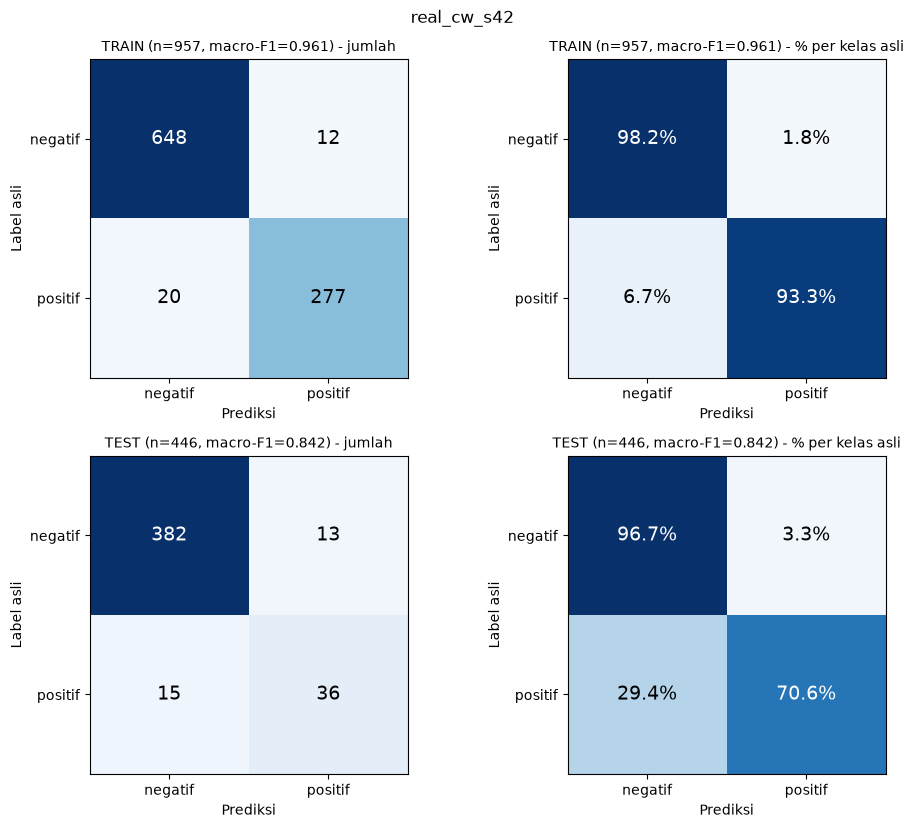

Train [asli     ] n= 957 | akurasi=96.7%


In [16]:
def pick_inspect_run():
    want = run_name(SYN_MODE, CLASS_WEIGHT, SEED)
    if (MODEL_DIR/want/"metrics.json").exists(): return want
    runs = sorted(MODEL_DIR.glob("*/metrics.json"), key=lambda p: p.stat().st_mtime)
    return runs[-1].parent.name if runs else None

RUN_TO_INSPECT = pick_inspect_run()       # ganti manual kalau mau run lain, mis. "targ_cw_s42"
print("Run yang diperiksa:", RUN_TO_INSPECT)

def plot_run(name):
    import matplotlib.pyplot as plt
    run_dir = MODEL_DIR / name
    info = json.load(open(run_dir/"metrics.json", encoding="utf-8"))
    train_df, val_df, test_df = load_data(info.get("syn_mode") or ("generic" if info.get("use_synthetic") else "none"))
    model = AutoModelForSequenceClassification.from_pretrained(run_dir/"best").to(DEVICE)
    names = ["negatif", "positif"]
    res = {"TRAIN": predict(model, make_loader(train_df, BATCH_SIZE*2))[:2],
           "TEST":  predict(model, make_loader(test_df,  BATCH_SIZE*2))[:2]}
    fig, axes = plt.subplots(2, 2, figsize=(10, 8.4))
    for r, (nama, (y, p)) in enumerate(res.items()):
        cm  = confusion_matrix(y, p, labels=[0, 1]); cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        mf1 = precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]
        for c, (data, title, fmt) in enumerate(((cm, "jumlah", "d"), (cmn, "% per kelas asli", ".1%"))):
            ax = axes[r, c]; ax.imshow(data, cmap="Blues", vmin=0, vmax=data.max())
            ax.set_xticks([0, 1], names); ax.set_yticks([0, 1], names)
            ax.set_xlabel("Prediksi"); ax.set_ylabel("Label asli")
            ax.set_title(f"{nama} (n={len(y)}, macro-F1={mf1:.3f}) - {title}", fontsize=10)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, format(data[i, j], fmt), ha="center", va="center", fontsize=14,
                            color="white" if data[i, j] > data.max()/2 else "black")
        print(f"{nama:5s}: acc={accuracy_score(y, p):.4f} | macro-F1={mf1:.4f} | recall negatif={cmn[0,0]:.1%} | recall positif={cmn[1,1]:.1%}")
    fig.suptitle(name); fig.tight_layout()
    fig.savefig(run_dir/"confusion_matrix_train_test.png", dpi=150); plt.show()
    y_tr, p_tr = res["TRAIN"]
    for s in ("asli", "synthetic", "targeted"):
        mk_ = (train_df["sumber"] == s).values
        if mk_.any(): print(f"Train [{s:9s}] n={mk_.sum():4d} | akurasi={accuracy_score(y_tr[mk_], p_tr[mk_]):.1%}")
    del model; free_mem()

if RUN_TO_INSPECT: plot_run(RUN_TO_INSPECT)

### Analisis error + threshold (satu run)

In [17]:
def show_errors(name, top=20):
    pred = pd.read_csv(MODEL_DIR/name/"test_predictions.csv", encoding="utf-8")
    is_pos = pred["asli"] == "positif"
    pd.set_option("display.max_colwidth", 130); pd.set_option("display.width", 250)
    print("prob_positif untuk positif asli:"); print(pred.loc[is_pos, "prob_positif"].describe().round(3))
    print("\nPositif asli yang diprediksi negatif:")
    print(pred[is_pos & (pred["prediksi"] == "negatif")].sort_values("prob_positif")[["comment_text", "prob_positif"]].head(top).to_string())
    print("\nNegatif asli yang diprediksi positif:")
    print(pred[~is_pos & (pred["prediksi"] == "positif")].sort_values("prob_positif", ascending=False)[["comment_text", "prob_positif"]].head(top).to_string())
    print("\nKalau threshold diturunkan:")
    for t in (0.5, 0.4, 0.3, 0.2, 0.1):
        hit = pred["prob_positif"] >= t
        tp = (is_pos & hit).sum(); fp = (~is_pos & hit).sum()
        print(f"  threshold {t}: recall={tp/max(is_pos.sum(),1):.1%} | precision={tp/max(tp+fp,1):.1%} | salah-positif={fp}")

if RUN_TO_INSPECT: show_errors(RUN_TO_INSPECT)

prob_positif untuk positif asli:
count    51.000
mean      0.681
std       0.356
min       0.007
25%       0.342
50%       0.893
75%       0.968
max       0.997
Name: prob_positif, dtype: float64

Positif asli yang diprediksi negatif:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

### Cek kebocoran kata kunci di data latih
Kalau satu kata (mis. `mbg`) hampir selalu muncul di satu label, model bisa belajar "ada kata itu → label itu" tanpa membaca isi kalimat.

In [18]:
KEYWORDS = ["mbg", "sppg", "dukung", "bagus", "?", "korup", "hutang"]
tr_all, va_all, _ = load_data("both")
tr_all = pd.concat([tr_all, va_all])
for sumber_filter, judul in ((None, "SEMUA data latih (asli + sintetis + targeted)"), ("asli", "hanya data ASLI"), ("targeted", "hanya TARGETED")):
    d = tr_all if sumber_filter is None else tr_all[tr_all["sumber"] == sumber_filter]
    if len(d) == 0: continue
    print(f"\n{judul} (n={len(d)}, % positif keseluruhan = {d['label'].mean():.0%})")
    for kw in KEYWORDS:
        m_ = d["text"].str.contains(kw, regex=False)
        if m_.sum(): print(f"  {kw!r:9}: {m_.sum():4d} komentar | % positif = {d.loc[m_, 'label'].mean():.0%}")
print("\nKomposisi sumber x label:")
print(tr_all.groupby(["sumber", "final_label"]).size().unstack(fill_value=0))


SEMUA data latih (asli + sintetis + targeted) (n=1580, % positif keseluruhan = 53%)
  'mbg'    :  170 komentar | % positif = 51%
  'sppg'   :    1 komentar | % positif = 0%
  'dukung' :   53 komentar | % positif = 85%
  'bagus'  :   15 komentar | % positif = 80%
  '?'      :   87 komentar | % positif = 30%
  'korup'  :   27 komentar | % positif = 52%

hanya data ASLI (n=1088, % positif keseluruhan = 31%)
  'mbg'    :   92 komentar | % positif = 9%
  'sppg'   :    1 komentar | % positif = 0%
  'dukung' :   27 komentar | % positif = 70%
  'bagus'  :    6 komentar | % positif = 50%
  '?'      :   67 komentar | % positif = 9%
  'korup'  :   26 komentar | % positif = 50%

hanya TARGETED (n=80, % positif keseluruhan = 100%)
  'mbg'    :   77 komentar | % positif = 100%
  'dukung' :    8 komentar | % positif = 100%
  'bagus'  :    3 komentar | % positif = 100%
  '?'      :   16 komentar | % positif = 100%

Komposisi sumber x label:
final_label  negatif  positif
sumber                       


### Laporan slice pada TEST: komentar yang memuat `mbg` / `?`
Jumlahnya kecil (lihat kolom n), jadi lihat arah, bukan satu angka.

In [19]:
def slice_report(names=None, keywords=("mbg", "?")):
    names = names or sorted(p.parent.name for p in MODEL_DIR.glob("*/test_predictions.csv"))
    for kw in keywords:
        print(f"\n--- slice '{kw}' di test ---")
        for name in names:
            pred = pd.read_csv(MODEL_DIR/name/"test_predictions.csv", encoding="utf-8")
            sub = pred[pred["comment_text"].str.lower().str.contains(kw, regex=False)]
            pos, neg = sub[sub["asli"] == "positif"], sub[sub["asli"] == "negatif"]
            rp = (pos["prediksi"] == "positif").mean() if len(pos) else float("nan")
            rn = (neg["prediksi"] == "negatif").mean() if len(neg) else float("nan")
            print(f"{name:16s} n={len(sub):3d} | positif asli={len(pos):2d} recall={rp:5.0%} | negatif asli={len(neg):3d} recall={rn:5.0%}")
slice_report()


--- slice 'mbg' di test ---
real_cw_s42      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
real_cw_s43      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
real_cw_s44      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s42   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s43   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s44   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
targ_cw_s42      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  94%
targ_cw_s43      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  94%
targ_cw_s44      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  90%

--- slice '?' di test ---
real_cw_s42      n= 39 | positif asli= 6 recall=  67% | negatif asli= 33 recall=  97%
real_cw_s43      n= 39 | positif asli= 6 recall=  83% | negatif asli= 33 recall=  97

### Uji pasangan minimal: kalimat sama, hanya topik diganti
Kalau `mbg` jauh lebih rendah dari topik lain padahal kalimatnya identik, model membaca topik, bukan sikap. Template di sini rapi dan mirip gaya data targeted, jadi kenaikan P(positif) belum tentu berarti stance dipahami; lengkapi dengan data asli.

In [20]:
def minimal_pair(names, topics=("mbg", "program ini", "infrastruktur", "ekonomi", "pendidikan", "bansos"),
                 templates=("{} bagus banget, saya dukung", "dukung {}, bermanfaat", "{} sangat membantu rakyat", "{} program bagus")):
    table = {}
    for name in names:
        if not (MODEL_DIR/name/"best").exists(): print("lewati (belum ada):", name); continue
        mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR/name/"best").to(DEVICE).eval()
        col = {}
        for tp in topics:
            ps = []
            for tpl in templates:
                e = tokenizer(prep(tpl.format(tp)), max_length=MAX_LEN, truncation=True, return_tensors="pt").to(DEVICE)
                with torch.no_grad(): ps.append(float(torch.softmax(mdl(**e).logits.float(), dim=1)[0, 1]))
            col[tp] = np.mean(ps)
        table[name] = col
        del mdl; free_mem()
    out = pd.DataFrame(table).round(2)
    print(f"Rata-rata P(positif) per topik ({len(templates)} template kalimat pendukung):"); print(out.to_string() if len(out) else "(belum ada run)")
    return out

_ = minimal_pair([run_name("none", True, SEED), run_name("targeted", True, SEED)])

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 595.95it/s]


Rata-rata P(positif) per topik (4 template kalimat pendukung):
               real_cw_s42  targ_cw_s42
mbg                   0.07         0.72
program ini           0.25         0.63
infrastruktur         0.23         0.58
ekonomi               0.39         0.63
pendidikan            0.30         0.67
bansos                0.26         0.63


### Coba komentar sendiri

In [23]:
def predict_text(model, t):
    model.eval()
    e = tokenizer(prep(t), max_length=MAX_LEN, truncation=True, return_tensors="pt").to(DEVICE)
    with torch.no_grad(): pr = torch.softmax(model(**e).logits.float(), dim=1)[0].cpu().numpy()
    return id2label[int(pr.argmax())], round(float(pr.max()), 3)

CONTOH = ["Pak Prabowo memang tegas, mantap 🇮🇩👏", "MBG bermanfaat atau tidakk??", "Dukung MBG bermanfaat",
          "saya dukung prabowo", "bagus programnya, semoga jalan", "tetep aja salah kalau di mata pembenci"]
if RUN_TO_INSPECT:
    _m = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR/RUN_TO_INSPECT/"best").to(DEVICE)
    for t in CONTOH: print(predict_text(_m, t), "|", t)
    del _m; free_mem()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 474.81it/s]


('positif', 0.99) | Pak Prabowo memang tegas, mantap 🇮🇩👏
('negatif', 0.994) | MBG bermanfaat atau tidakk??
('negatif', 0.973) | Dukung MBG bermanfaat
('positif', 0.933) | saya dukung prabowo
('negatif', 0.807) | bagus programnya, semoga jalan
('negatif', 0.913) | tetep aja salah kalau di mata pembenci


In [22]:
print("Selesai.\n")
print("Folder project :", ROOT)
print("Data & model   :", DATA_DIR)
print("Run tersimpan  :", sorted(p.parent.name for p in MODEL_DIR.glob("*/metrics.json")))
print("\nSebelum commit ke GitHub: Kernel > Clear All Outputs (output memuat potongan komentar & path komputermu).")

Selesai.

Folder project : C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment
Data & model   : C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment\data\praprocessing\labels_shafwa_hans_agreement
Run tersimpan  : ['real_cw_s42', 'real_cw_s43', 'real_cw_s44', 'synth_nocw_s42', 'synth_nocw_s43', 'synth_nocw_s44', 'targ_cw_s42', 'targ_cw_s43', 'targ_cw_s44']

Sebelum commit ke GitHub: Kernel > Clear All Outputs (output memuat potongan komentar & path komputermu).
